<a href="https://colab.research.google.com/github/oscartm1996/Circular-Waveguide-Electromagnetic-Mode-TM-Analysis/blob/main/GUIA_DE_ONDA_CIRCULAR_MODOS_MT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install chart_studio
!pip install matplotlib
import chart_studio
chart_studio.tools.set_credentials_file(username='OSCART0B4R', api_key='ZmSU7HZOkGermCAKSrSy')
from scipy.special import gamma, factorial
!pip install numpy
!pip install scipy
from scipy.special import factorial

In [ ]:
import plotly
import plotly.io as pio
import plotly.graph_objs as go
import chart_studio.plotly as py
import plotly.tools as tls
import plotly.figure_factory as ff
import copy
import pandas as pd
import numpy as np
from numpy import pi, sin, cos, sqrt
import math
import cmath
import matplotlib.pyplot as plt

**GUIA DE ONDA SECCION CIRCULAR**

Ecuacion Diferencial Radial:

$\rho^2\frac{\partial^2R(\rho)}{\partial \rho^2}+\rho\frac{\partial R(\rho)}{\partial \rho}+(\gamma^2 \rho^2-k_{\phi}^2)R(\rho)=0$


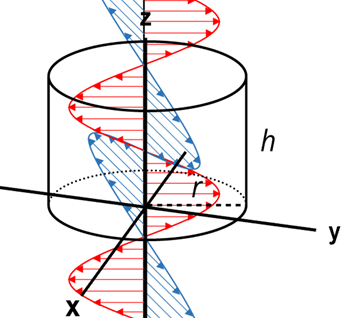

**INTRODUZCA DATOS**:

In [ ]:
r=float(input('INTRODUZCA RADIO a DEL CILINDRO EN μMETROS r= '))
#L=float(input('INTRODUZCA LONGITUD FIBRA L(Direccion z) DEL CILINDRO EN μMETROS L= '))
m=int(input('INTRODUZCA VECTOR DE ONDA ASIMUTAL m (SOLO VALORES ENTEROS POSITIVOS m>=0) m= '))
nth=int(input('INTRODUZCA n-esima (RAIZ DE LA SERIE DE BESSEL SOLO ENTEROS POSITIVOS nth>=1) n= '))
w=float(eval(input('INTRODUZCA LA FRECUENCIA ANGULA11R w DE LA ONDA ELECTROMAGNETICA w= ')))
ep=float(input('INTRODUZCA LA PERMITIVAD ELECTRICA RELATIVA (Vacio ɛr=1) ɛr= '))
mu=float(input('INTRODUZCA LA PERMEABILIDAD MAGNETICA RELATIVA (Vacio μr=1) μr= '))
Amn=float(eval(input('INTRODUZCA LA INTENSIDAD DE CAMPO ELECTRICO [V/m]] Ez0= ')))

INTRODUZCA RADIO a DEL CILINDRO EN μMETROS r= 500
INTRODUZCA VECTOR DE ONDA ASIMUTAL m (SOLO VALORES ENTEROS POSITIVOS m>=0) m= 3
INTRODUZCA n-esima (RAIZ DE LA SERIE DE BESSEL SOLO ENTEROS POSITIVOS nth>=1) n= 2
INTRODUZCA LA FRECUENCIA ANGULA11R w DE LA ONDA ELECTROMAGNETICA w= 10**15
INTRODUZCA LA PERMITIVAD ELECTRICA RELATIVA (Vacio ɛr=1) ɛr= 1.5
INTRODUZCA LA PERMEABILIDAD MAGNETICA RELATIVA (Vacio μr=1) μr= 1
INTRODUZCA LA INTENSIDAD DE CAMPO ELECTRICO [V/m]] Ez0= 10**9


Solucion Radial:
$R(\rho)= C_1 J_{k_{ϕ}}(\rho)+C_2 J_{-k_{ϕ}}(\rho)$


Donde:
$J_{k_{ϕ}}(\rho)= a_0 ρ^{k_{ϕ}}∑_{n=0}^{∞}\frac{(-1)^{n}Γ(1+k_{ϕ})}{n!Γ(n+1+k_{ϕ})}(\frac{ργ}{2})^{2n}$

$J_{-k_{ϕ}}(\rho)= a_0 ρ^{-k_{ϕ}}∑_{n=0}^{∞}\frac{(-1)^{n}Γ(1-k_{ϕ})}{n!Γ(n+1-k_{ϕ})}(\frac{ργ}{2})^{2n}$

$k_{ϕ}=m=0,1,2,3,...,n$

$J_{m}(p)=a_{0}\sum_{n=0}\frac{(-1)^{n}m!}{(m+n)!n!}ρ^{2n+m}(\frac{γ}{2})^{2n}$

Aplicando condiciones de frontera
$J_{m}=0$

$J_{m}(a)=0=a_{0}\sum_{n=0}\frac{(-1)^{n}m!}{(m+n)!n!}a^{2n+m}(\frac{γ}{2})^{2n}$

Encontrar $γ$ que satisfaga esa condicion.

Por Newthon-Raphson


$f(\gamma_{i})=\sum_{n=0}\frac{(-1)^{n}m!}{(m+n)!n!}a^{2n+m}(\frac{γ_i}{2})^{2n}$

$f^{'}(\gamma_{i})=\sum_{n=0}\frac{(-1)^{n}m!}{(m+n)!(n-1)!}a^{2n+m}(\frac{γ_i}{2})^{2n-1}$

In [ ]:
#Valores Constantes mu:Permeabilidad magnetica, ep:Permitividad electrica
ep=ep*(8.854*10**(-12))*(10**(-18))    #(c s)^2/(kg μm^3)
mu=mu*(4*math.pi*10**(-7))/(10**(-6))      #(kg μm)/c^2
Amn=Amn*10**(6)     #[Ez0]=kg μm/(s^2 c)
C2=1
D2=1
L=6*r

#Funcion que calcula los ceros de la funcion de Bessel a traves del metodo Newton-Raphson.
def NRfuncion(y,m):
  fx=0
  dfx=0
  for n in range(50):
    fx+=((((-1)**n)*factorial(m))/(factorial(m+n)*factorial(n)))*(a**(2*n+m))*((y/2)**(2*n))
    dfx+=((((-1)**n)*n*factorial(m))/(factorial(m+n)*factorial(n))*(a**(2*n+m)))*((y/2)**(2*n-1))
  return fx,dfx

#Funcion que calcula la funcion de Bessel y su derivada.
def besselfuncion(p, y, m):
  jb = 0
  djb = 0
  for n in range(50):
    jb += ((((-1)**n)*factorial(m))/(factorial(m+n)*factorial(n)))*(p**(2*n+m))*((y/2)**(2*n))
    if p == 0 and (2*n+m-1) < 0:
      djb_term = 0
    else:
      djb_term = ((((-1)**n)*factorial(m)*(2*n+m))/(factorial(m+n)*factorial(n)))*(p**(2*n+m-1))*((y/2)**(2*n))
    djb += djb_term
  return jb, djb

#Algoritmo para elegir el n-esima raiz de Bessel
x4=np.zeros(100)
a=1
ki=0
ynth=0.01
while ki<nth:
  if NRfuncion(ynth,m)[0]*NRfuncion(ynth+0.1,m)[0]<=0:
    yi=ynth
    for i in range(50):
      fxi, dfxi=NRfuncion(yi,m)
      yi1=yi-fxi/dfxi
      yi=yi1

    yr=yi1
    yi1=0
    ki+=1
  ynth+=0.1
  if ki>=1:
    x4[ki-1]=yr

#n-esima raiz de Bessel resultante
print("Derivada Funcion de Bessel Zero dχmn= ", yr)
print("Frecuencia de Corte fc= ",yr/(2*math.pi*r*math.sqrt(mu*ep)))
yr=yr/r

Derivada Funcion de Bessel Zero dχmn=  9.761023129981554
Frecuencia de Corte fc=  760545408574.038


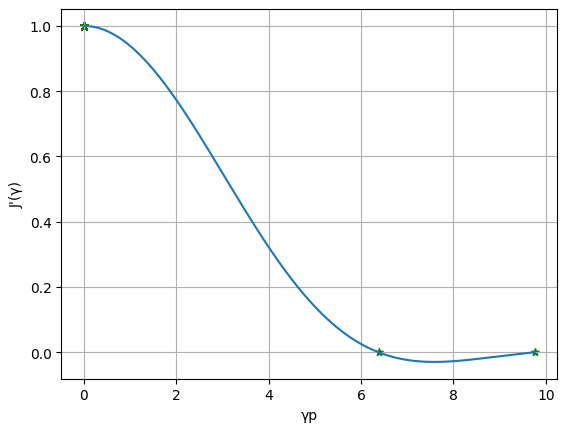

In [ ]:
#Grafica de la funcion de Bessel
x1 = np.arange(0, x4[nth-1], 0.01)
y1 = besselfuncion(1,x1,m)[0]

y4=besselfuncion(1,x4,m)[0]

plt.scatter(x4, y4, label= "stars", color= "green",
            marker= "*", s=30)
plt.plot(x1, y1)
plt.grid(True)
plt.xlabel("γp")
plt.ylabel("J'(γ)")
plt.show()


$k=\sqrt{μɛ w^2 - \gamma_{mn}}$

donde $n$ es el n-ésima raiz de la funcion de Bessel

$E_{z}=A_{mn}J_{m}(\rho)[A_{0}cos(m\phi)+B_{0}sen(m\phi)]e^{ikz-i\omega t}$

$E_{\rho}=-A_{mn}\frac{jk_{z}}{\gamma_{\rho}}J_{m}^{'}(\gamma_{\rho}\rho)(C_{2}cos(m\phi)+D_{2}sin(m\phi))e^{-jk_{z}z}$

$E_{\phi}=-A_{mn}\frac{jk_{z}m}{\gamma_{\rho}^{2}\rho}J_{m}(\gamma_{\rho}\rho)(-C_{2}sin(m\phi)+D_{2}cos(m\phi))e^{-jk_{z}z}$

$H_{\rho}=A_{mn}\frac{j \omega \epsilon m}{\gamma_{\rho}^{2}\rho}J_{m}(\gamma_{\rho}\rho)(-C_{2}sin(m\phi)+D_{2}cos(m\phi))e^{-jk_{z}z}$

$H_{\phi}=-A_{mn}\frac{j\omega \epsilon}{\gamma_{\rho}}J_{m}^{'}(\gamma_{\rho}\rho)(C_{2}cos(m\phi)+D_{2}sin(m\phi))e^{-jk_{z}z}$

$H_{z}=0$


/tmp/ipykernel_4338/3975884006.py:14: RuntimeWarning:

divide by zero encountered in divide

/tmp/ipykernel_4338/3975884006.py:14: RuntimeWarning:

invalid value encountered in divide

/tmp/ipykernel_4338/3975884006.py:14: RuntimeWarning:

invalid value encountered in multiply

/tmp/ipykernel_4338/3975884006.py:17: RuntimeWarning:

divide by zero encountered in divide

/tmp/ipykernel_4338/3975884006.py:17: RuntimeWarning:

invalid value encountered in divide

/tmp/ipykernel_4338/3975884006.py:17: RuntimeWarning:

invalid value encountered in multiply



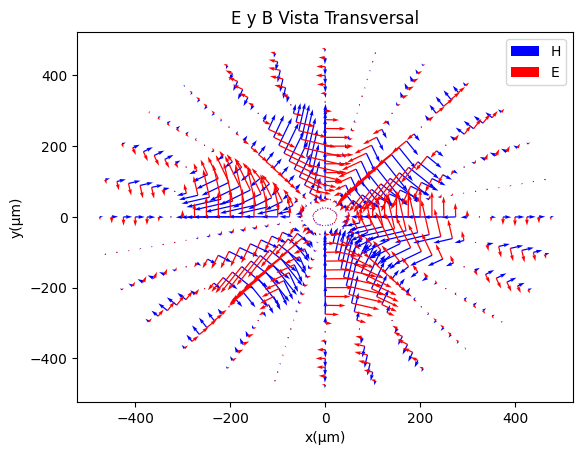

In [ ]:
#Calculo Kz
k=cmath.sqrt(mu*ep*(w**2)-(yr**2))
#Crear red 3D argumentos de los vectores posicion
rho, phi, z = np.meshgrid(np.arange(0, r, r/20),
                          np.arange(0, 2*3.1416,2*3.1416/28 ),
                          np.arange(0, L, L/25))
rho=np.abs(rho)

besselfuncion_vectorized = np.vectorize(besselfuncion)

jb = besselfuncion_vectorized(rho,yr,m)[0]
djb = besselfuncion_vectorized(rho,yr,m)[1]
Ep = np.real(((-Amn*1j*k)/yr) *djb * (C2*np.cos(phi*m)+D2*np.sin(phi*m))*np.exp(1j*k*z))
Ephi = np.real(((-Amn*1j*k*m)/((yr**2)*rho)) *jb * (-C2*np.sin(phi*m)+D2*np.cos(phi*m))*np.exp(1j*k*z))
Ez = np.real(Amn *jb * (C2*np.cos(phi*m)+D2*np.sin(phi*m))*np.exp(1j*k*z))

Hp = np.real(((Amn*1j*w*ep*m)/((yr**2)*rho)) *jb * (-C2*np.sin(phi*m)+D2*np.cos(phi*m))*np.exp(1j*k*z))
Hphi = np.real(((-Amn*1j*w*ep)/(yr)) *djb * (C2*np.cos(phi*m)+D2*np.sin(phi*m))*np.exp(1j*k*z))
Hz = np.zeros_like(Hp)

x=rho*np.cos(phi)
y=rho*np.sin(phi)

Hx=(Hp*np.cos(phi)+Hphi*np.sin(phi))*10**(6)
Hy=(-Hp*np.sin(phi)+Hphi*np.cos(phi))*10**(6)
Ez=Ez*10**(-6)
Ex=(Ep*np.cos(phi)+Ephi*np.sin(phi))*10**(-6)
Ey=(-Ep*np.sin(phi)+Ephi*np.cos(phi))*10**(-6)

#Calculo de la Energia

shape = Ex.shape  # Obtiene la forma de los arrays de entrada
E = np.zeros(shape + (3,))  # Crea un array con una dimensión extra para las componentes (x, y, z)
H = np.zeros(shape + (3,))

#Asigna las componentes a los arrays E y H
E[..., 0] = Ex
E[..., 1] = Ey
E[..., 2] = Ez
H[..., 0] = Hx
H[..., 1] = Hy
H[..., 2] = Hz

# Calcula el producto cruz
S = np.cross(E, H)  # S tendrá la misma forma que Ex, Ey, Ez, etc.
S = np.nan_to_num(S, nan=0)
#print(S)

# Calcula la magnitud del vector S
magnitude = np.sqrt(np.sum(S**2, axis=-1))

# Encuentra la magnitud máxima
max_magnitude = np.max(magnitude)

# Ajusta el sizeref en función de la magnitud máxima
sizeref =  1* max_magnitude / np.max(np.abs(S))

##################################### GRAFICA 2D #######################################
x1=np.array
y1=np.array
z1=np.array
Hx1=np.array
Hy1=np.array
Ex1=np.array
Ey1=np.array

x1=x[:,:,1]
y1=y[:,:,1]
z1=z[:,:,1]
Hx1=Hx[:,:,1]
Hy1=Hy[:,:,1]
Ex1=Ex[:,:,1]
Ey1=Ey[:,:,1]

plt.quiver(x1, y1, Hx1, Hy1, color='b', label='H')
plt.quiver(x1, y1, Ex1, Ey1, color='r', label='E')
plt.xlabel('x(μm)')
plt.ylabel('y(μm)')
plt.title('E y B Vista Transversal')
plt.legend()
plt.show()


In [ ]:
#GRAFICA 3D AJUSTE DE EJES
def flatten_vf(x, y, z, Hx, Hy, Hz):
    return x.flatten(), y.flatten(), z.flatten(), Hx.flatten(), Hy.flatten(), Hz.flatten()

xB, yB, zB, Hx, Hy, Hz = flatten_vf(x, y, z, Hx, Hy, Hz)
xB, yB, zB, Ex, Ey, Ez = flatten_vf(x, y, z, Ex, Ey, Ez)

magnitudes_H = np.sqrt(Hx**2 + Hy**2 + Hz**2)
mask_H = np.isfinite(magnitudes_H)
xB_H, yB_H, zB_H = xB[mask_H], yB[mask_H], zB[mask_H]
Hx, Hy, Hz = Hx[mask_H], Hy[mask_H], Hz[mask_H]
magnitudes_H = magnitudes_H[mask_H]

magnitudes_E = np.sqrt(Ex**2 + Ey**2 + Ez**2)
mask_E = np.isfinite(magnitudes_E)
xB_E, yB_E, zB_E = xB[mask_E], yB[mask_E], zB[mask_E]
Ex, Ey, Ez = Ex[mask_E], Ey[mask_E], Ez[mask_E]
magnitudes_E = magnitudes_E[mask_E]

max_magnitude_H = magnitudes_H.max()
sizeref_H = 2* max_magnitude_H

max_magnitude_E = magnitudes_E.max()
sizeref_E = 2* max_magnitude_E

trace_H = go.Cone(
    x=xB_H,
    y=yB_H,
    z=zB_H,
    u=Hx,
    v=Hy,
    w=Hz,
    sizemode='absolute',
    sizeref=sizeref_H,
    showscale=True,
    colorscale='Reds',
    anchor='tail',
    name='H Field',
    colorbar=dict(x=1.2, title='H (A/m)')
)

trace_E = go.Cone(
    x=xB_E,
    y=yB_E,
    z=zB_E,
    u=Ex,
    v=Ey,
    w=Ez,
    sizemode='absolute',
    sizeref=sizeref_E,
    showscale=True,
    colorscale='Blues',
    anchor='tail',
    name='E Field',
    colorbar=dict(x=1.1, title='E (V/m)')
)

fig2 = go.Figure(data=[trace_H, trace_E])

fig2.update_layout(
    scene=dict(
        xaxis=dict(range=[min(xB_H ), max(xB_H)],title='x(μm)'),
        yaxis=dict(range=[min(yB_H ), max(yB_H)],title='y(μm)'),
        zaxis=dict(range=[min(zB_H ), max(zB_H)],title='z(μm)'),
        aspectmode='data'
    )
)

title = 'Vertical levels of a numerical weather model'
pio.show(fig2)


In [ ]:
#Figura Vector de Poyting
fig = go.Figure(data=[go.Cone(
    x=x.flatten(),
    y=y.flatten(),
    z=z.flatten(),
    u=S[..., 0].flatten(),
    v=S[..., 1].flatten(),
    w=S[..., 2].flatten(),
    sizemode='scaled',
    sizeref=sizeref,
    showscale=True,
    colorscale='Viridis',
    colorbar=dict(x=1, title='S (J)')
)
])
fig.update_layout(
    scene=dict(
        xaxis=dict(title='x(μm)'),
        yaxis=dict(title='y(μm)'),
        zaxis=dict(title='z(μm)'),
        aspectmode='data'
    )
)

fig.show()


In [ ]:
fig3 = go.Figure(data=[trace_H])
title = 'Campo Magnetico'
pio.show(fig3, filename='Campo Magnetico', validate=False)

In [ ]:
fig4 = go.Figure(data=[trace_E])
title = 'Campo Electrico'
pio.show(fig4, filename='Campo Electrico', validate=False)